# Mini-project 2: Solar micro-grid dispatch planner

In [7]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise FileNotFoundError("Open Jupyter in the correct folder")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import statistics
import timeit
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import linalg
from src.microgrid import MicroGrid, generate_demands, get_demand, read_demands, describe

grid = MicroGrid()
det, condition = grid.diagnostics()
print("A =\n", grid.matrix, "\ndeterminant:", det, "condition number:", condition)
print("Nonzero determinant means a unique algebraic solution; condition number describes sensitivity to demand noise.")
print("Hand check: 3×20+2×10=80, 4×20+10=90; solution:", grid.solve_day(80, 90))

# Set True to enter D1 and D2 manually; False keeps Restart & Run All non-interactive.
RUN_INTERACTIVE = False
if RUN_INTERACTIVE:
    d1 = get_demand()
    d2 = get_demand()
    print("Interactive dispatch:", grid.solve_day(d1, d2))
else:
    print("Interactive input is available: change RUN_INTERACTIVE to True.")

A =
 [[3. 2.]
 [4. 1.]] 
determinant: -4.999999999999999 condition number: 5.82842712474619
Nonzero determinant means a unique algebraic solution; condition number describes sensitivity to demand noise.
Hand check: 3×20+2×10=80, 4×20+10=90; solution: {'solar': np.float64(20.0), 'battery': np.float64(10.0), 'infeasible': False, 'residual': 0.0}
Interactive input is available: change RUN_INTERACTIVE to True.


## Reproducible CSV and solution strategies

The seeded generator builds weekday/weekend patterns from plausible non-negative solar and battery values, then derives D1/D2. Two deliberately inconsistent days test the infeasible-day policy. For those days, non-negative least squares (NNLS) minimizes remaining unmet equations and **reports the residual**, rather than pretending both exact equalities still hold.

In [4]:
path = ROOT / "data" / "microgrid_30_days.csv"
generate_demands(str(path), seed=42)
demands = read_demands(str(path))
assert len(demands) == 30

loop_solutions = np.array([linalg.solve(grid.matrix, row) for row in demands])
# One SciPy call solves the same 30 systems when columns contain daily demands.
vector_solutions = linalg.solve(grid.matrix, demands.T).T
assert np.allclose(loop_solutions, vector_solutions)
loop_time = timeit.timeit(lambda: [linalg.solve(grid.matrix, row) for row in demands], number=500)
vector_time = timeit.timeit(lambda: linalg.solve(grid.matrix, demands.T), number=500)
print(f"500 repeats: loop {loop_time:.4f}s; vectorised {vector_time:.4f}s (machine-dependent)")

dispatch = [grid.solve_day(*row) for row in demands]
frame = pd.DataFrame(dispatch)
frame.insert(0, "day", np.arange(1, 31))
frame["daily_cost_UGX"] = 150*frame["solar"]+450*frame["battery"]
print("Infeasible days (NNLS values are not exact equality solutions):")
print(frame.loc[frame.infeasible, ["day", "solar", "battery", "residual"]].round(2).to_string(index=False))
print("Solar (kWh):", describe(frame.solar))
print("Battery (kWh):", describe(frame.battery))
print("More volatile by standard deviation:", "solar" if statistics.stdev(frame.solar)>statistics.stdev(frame.battery) else "battery")
print("Illustrative 30-day bill (UGX):", round(frame.daily_cost_UGX.sum()))
print("Example first-day cost (UGX):", round(frame.daily_cost_UGX.iloc[0]))

500 repeats: loop 1.7182s; vectorised 0.0485s (machine-dependent)
Infeasible days (NNLS values are not exact equality solutions):
 day  solar  battery  residual
  10  37.64      0.0     10.45
  24  37.91      0.0     10.53
Solar (kWh): {'mean': 24.365147999999998, 'variance': 18.70840815637517, 'std_dev': 4.325321740214845}
Battery (kWh): {'mean': 16.73458666666667, 'variance': 24.909453881195407, 'std_dev': 4.990937174639189}
More volatile by standard deviation: battery
Illustrative 30-day bill (UGX): 335560
Example first-day cost (UGX): 10581


## Dispatch and optional sensitivity extension

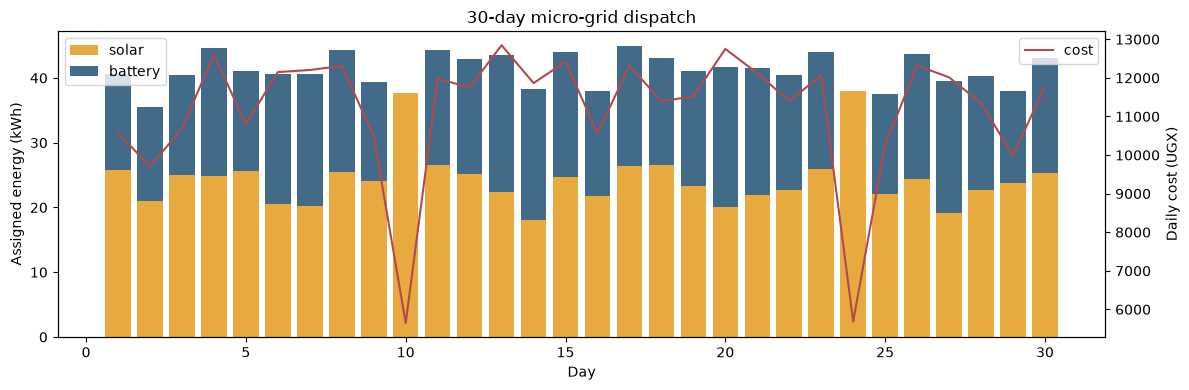

First-day nominal dispatch: {'solar': np.float64(25.7224), 'battery': np.float64(14.938399999999996), 'infeasible': False, 'residual': 0.0}
Sensitivity 5th/95th percentiles (raw algebraic x, y):
[[23.31  9.78]
 [28.14 20.28]]


In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(frame.day, frame.solar, label="solar", color="#e8aa3e")
ax.bar(frame.day, frame.battery, bottom=frame.solar, label="battery", color="#426b89")
ax.set(xlabel="Day", ylabel="Assigned energy (kWh)", title="30-day micro-grid dispatch")
right = ax.twinx()
right.plot(frame.day, frame.daily_cost_UGX, color="#b2494d", label="cost")
right.set_ylabel("Daily cost (UGX)")
ax.legend(loc="upper left")
right.legend(loc="upper right")
fig.tight_layout()
plt.show()

# Extension: perturb each demand independently by ±5% across 1,000 draws.
rng = np.random.default_rng(2026)
test_day = demands[0]
perturbed = test_day*(1+rng.uniform(-.05, .05, size=(1000, 2)))
solved = grid.solve_many(perturbed)
print("First-day nominal dispatch:", grid.solve_day(*test_day))
print("Sensitivity 5th/95th percentiles (raw algebraic x, y):")
print(np.percentile(solved, [5, 95], axis=0).round(2))

## Findings & Limitations

The determinant of the coefficient matrix is −5, so each daily pair of demand equations has one algebraic solution. The finite condition number indicates that small changes to the right-hand side generally produce bounded changes in the solution, although the Monte Carlo table shows the actual scale under ±5% independent demand changes. The loop and vectorised SciPy results agree. Timing numbers are machine-dependent, but the vectorised call avoids 30 separate calls per run; timing just 30 observations should not be generalized to large systems.

Two generated days deliberately produce a negative energy source in the raw solution. Negative solar or battery supply is physically meaningless. The NNLS fallback assigns non-negative values, flags the day, and reports the mismatch to the original equalities; this residual must be treated as unmet model constraints, not hidden as a valid dispatch. The 30-day cost sums daily solar at UGX 150/kWh and battery at UGX 450/kWh, making the more expensive source visible in the bill. Standard deviation compares absolute day-to-day dispersion in kWh; relative volatility would require CV.

The two equations are illustrative constraints, not an optimized micro-grid with battery state of charge, solar availability, charge/discharge losses, maintenance, or emergency loads. An operator would need those constraints before using these allocations for a real health centre. The optional Monte Carlo exercise perturbs demand only; it does not quantify generation uncertainty.